# Lecture 7 — Class Exercise
## Part-to-Whole: Hierarchical Visualization

> **Push to:** `week07/lecture07_exercise.ipynb`


In [1]:
import pandas as pd
import plotly.express as px
import numpy as np

# Dataset: Global Energy Mix by Country and Source
df = pd.read_csv('../data/global_energy_mix.csv')

# Source type mapping — reuse from lecture
source_category = {
    'Coal': 'Fossil', 'Oil': 'Fossil', 'Natural Gas': 'Fossil',
    'Nuclear': 'Low-carbon', 'Hydro': 'Low-carbon',
    'Wind': 'Renewable', 'Solar': 'Renewable', 'Other Renewables': 'Renewable'
}
df['Source_Type'] = df['Source'].map(source_category)

print(f"Loaded: {len(df)} rows")
print(df.head(10))


Loaded: 103 rows
         Country         Region            Source  Share_pct     TWh  \
0  United States  North America              Coal         10  1015.0   
1  United States  North America               Oil         35  3220.0   
2  United States  North America       Natural Gas         34  3083.0   
3  United States  North America           Nuclear          9   798.0   
4  United States  North America             Hydro          3   339.0   
5  United States  North America              Wind          4   413.0   
6  United States  North America             Solar          3   325.0   
7  United States  North America  Other Renewables          2   229.0   
8          China           Asia              Coal         58  6929.1   
9          China           Asia               Oil         18  1620.0   

  Source_Type  
0      Fossil  
1      Fossil  
2      Fossil  
3  Low-carbon  
4  Low-carbon  
5   Renewable  
6   Renewable  
7   Renewable  
8      Fossil  
9      Fossil  


## Task 1 — Treemap: fossil fuel dependency by country

**What to build:** A treemap showing **fossil fuel TWh only**, broken down by Region → Country → Source (Coal / Oil / Natural Gas).

**Requirements:**
- Filter to fossil sources only before plotting
- Use `path=['Region', 'Country', 'Source']` for the hierarchy
- Colour encodes the fossil source type (Coal / Oil / Natural Gas) with a CVD-safe palette
- Show TWh values in labels — no percentages
- Grey out parent nodes (Region and Country level)
- Insight title naming which region or country is most fossil-dependent

> 💡 `df.loc[df['Source_Type'] == 'Fossil']`


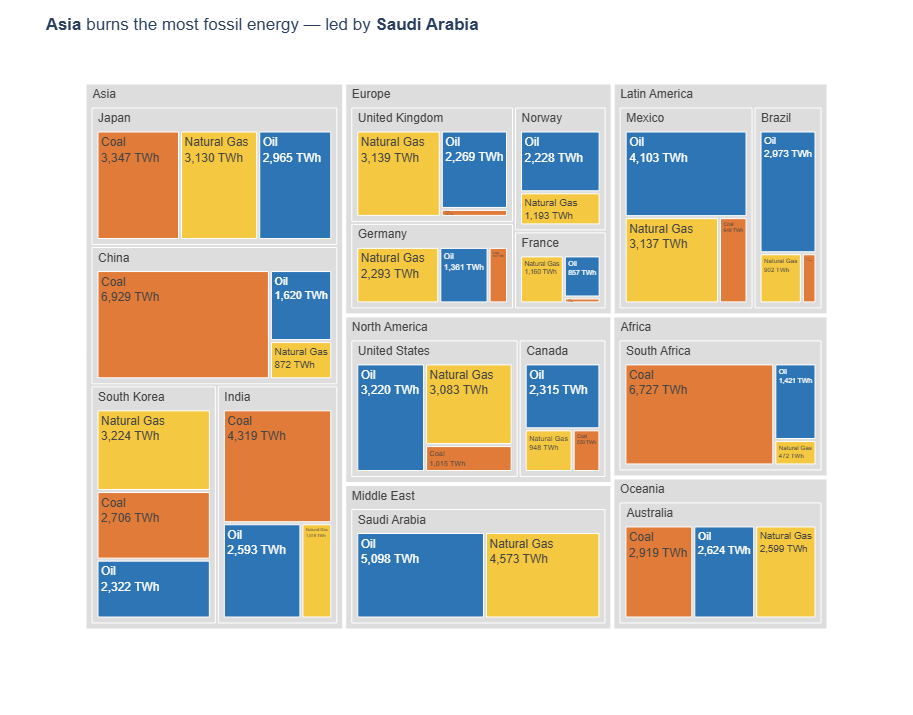

In [2]:
# Task 1
# YOUR CODE HERE

df_fossil = df.loc[df['Source_Type'] == 'Fossil'].copy()

fossil_colors = {
    'Coal':        '#E07B39',   # orange
    'Oil':         '#2E75B6',   # blue
    'Natural Gas': '#F5C842',   # yellow
}

top_region  = df_fossil.groupby('Region')['TWh'].sum().idxmax()
top_country = df_fossil.groupby('Country')['TWh'].sum().idxmax()

fig = px.treemap(
    df_fossil,
    path=['Region', 'Country', 'Source'],
    values='TWh',
    color='Source',
    color_discrete_map=fossil_colors,
    height=700, width=1100,
    template='plotly_white',
)

fig.update_traces(
    texttemplate='%{label}<br>%{value:,.0f} TWh',     # TWh only, no percentages
    hovertemplate='<b>%{label}</b><br>%{value:,.0f} TWh<extra></extra>',
    root_color='white',
)

fig.data[0].marker.colors = [
    c if c in fossil_colors.values() else '#DDDDDD'
    for c in fig.data[0].marker.colors
]

fig.update_layout(
    title=f'<b>{top_region}</b> burns the most fossil energy — led by <b>{top_country}</b>',
    font=dict(family='Arial', size=12),
)
fig.show()

## Task 2 — Treemap vs bar: low-carbon energy by country

**What to build:** Build **both** a treemap and a horizontal bar chart showing total low-carbon TWh (Nuclear + Hydro) per country. Then answer the question in a markdown cell below.

**Requirements:**
- Filter to `Source_Type == 'Low-carbon'` and aggregate TWh by country
- Treemap: single-level `path=['All', 'Country']` with a dummy root node labelled `'Low-carbon'`
- Bar chart: sorted by TWh, horizontal orientation, CVD-safe colour
- Both charts show TWh values, not percentages
- Insight title on the bar chart naming the leading country

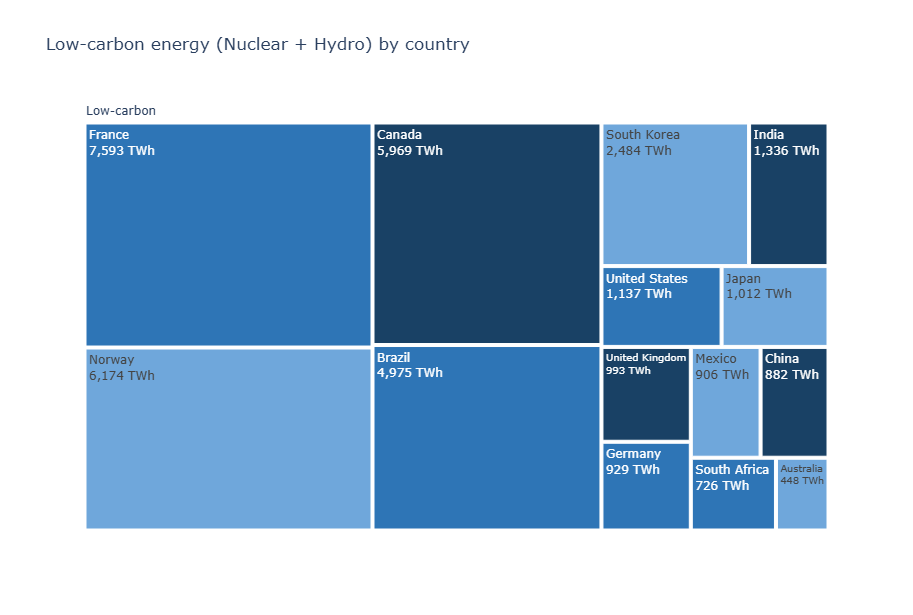

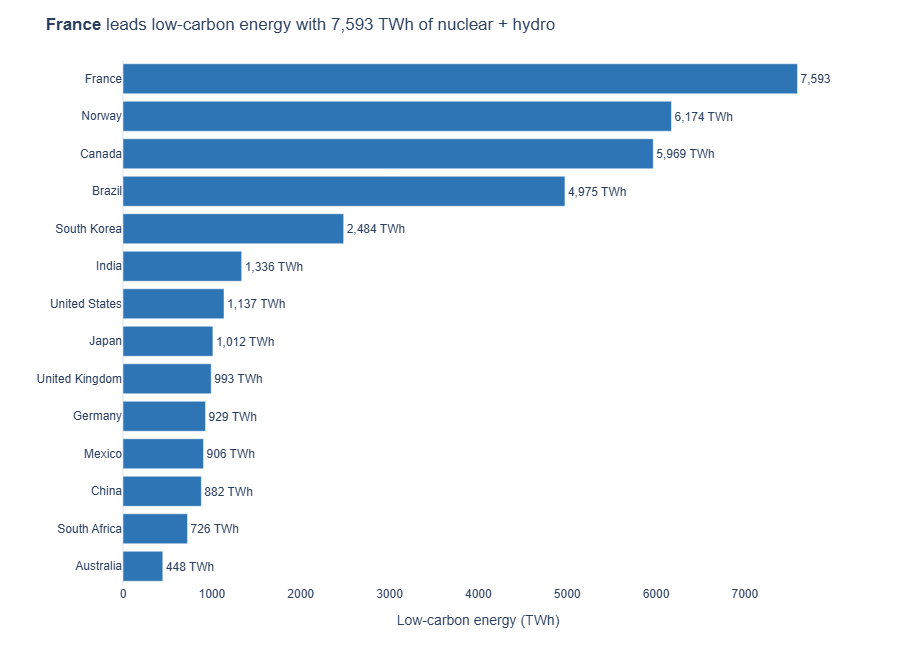

In [3]:
# Task 2 — charts
# YOUR CODE HERE
df_low = (df.loc[df['Source_Type'] == 'Low-carbon']
            .groupby('Country', as_index=False)['TWh'].sum()
            .sort_values('TWh', ascending=False))
df_low['All'] = 'Low-carbon'          # dummy root node

fig_tm = px.treemap(
    df_low,
    path=['All', 'Country'],
    values='TWh',
    color_discrete_sequence=['#2E75B6'],   # blue = low-carbon
    height=600, width=1000,
    template='plotly_white',
    title='Low-carbon energy (Nuclear + Hydro) by country',
)
fig_tm.update_traces(
    texttemplate='%{label}<br>%{value:,.0f} TWh',
    hovertemplate='<b>%{label}</b><br>%{value:,.0f} TWh<extra></extra>',
    root_color='white',
)
fig_tm.show()

leader = df_low.iloc[0]

fig_bar = px.bar(
    df_low,
    x='TWh', y='Country',
    orientation='h',
    text='TWh',
    color_discrete_sequence=['#2E75B6'],
    category_orders={'Country': df_low['Country'].tolist()},   # largest at the top
    labels={'TWh': 'Low-carbon energy (TWh)'},
    height=650, width=1000,
    template='plotly_white',
)
fig_bar.update_traces(texttemplate='%{text:,.0f} TWh', textposition='outside')
fig_bar.update_layout(
    title=f'<b>{leader["Country"]}</b> leads low-carbon energy with {leader["TWh"]:,.0f} TWh of nuclear + hydro',
    font=dict(family='Arial', size=12),
    yaxis=dict(title=''),
    xaxis=dict(showgrid=False),
)
fig_bar.show()

### Task 2 — reflection

**Which chart tells the ranking story more clearly, and why?**

The horizontal bar chart is better at explaining the story more clearly, since through the use of length, it can properly depict the quantity of carbon energy, and it visually easier for the viewer. Treemap on the other hand requires a lot more concentration by the viewer to understand the heirarchy of the countries in terms of carbon.

## Task 3 — 100% stacked bar: which region relies most on coal?

**What to build:** A horizontal 100% stacked bar chart showing, for each **Region**, how its fossil energy splits between Coal, Oil and Natural Gas. This is the **same data as your Task 1 treemap**, visualised a second way.

**Requirements:**
- Reuse `df_fossil` from Task 1; aggregate TWh by `Region` × `Source` and convert to **shares of each region's fossil total**
- Horizontal bars, regions **sorted by coal share** (highest at the top)
- Coal is the segment on the baseline (first in `category_orders`) and the **only coloured segment** — keep it the same colour as in Task 1; Oil and Natural Gas in two greys
- Percentage labels on the coal segments only
- Insight title naming the most coal-dependent region and its coal share

> 💡 `df.groupby('Region')['TWh'].transform('sum')` gives each row its region total

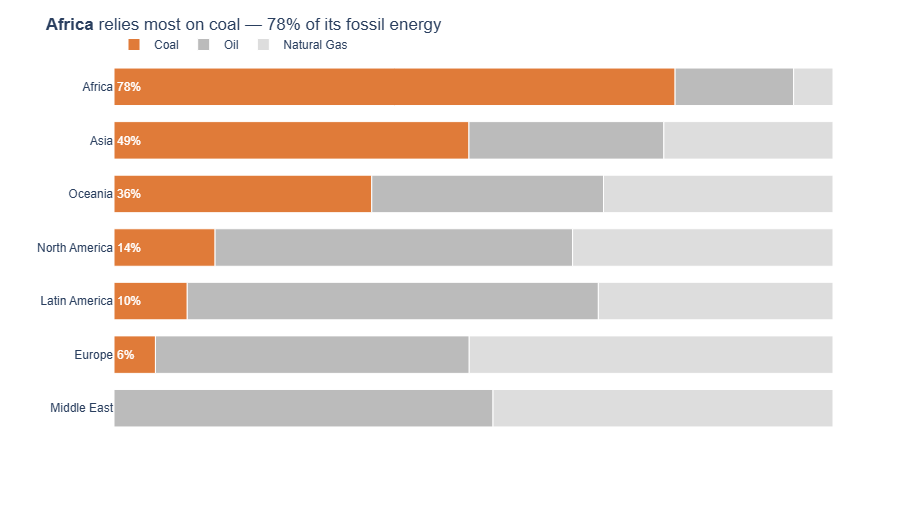

In [5]:
# Task 3
# YOUR CODE HERE

reg = df_fossil.groupby(['Region', 'Source'], as_index=False)['TWh'].sum()
reg['Share'] = reg['TWh'] / reg.groupby('Region')['TWh'].transform('sum')

coal_share = (reg.pivot_table(index='Region', columns='Source', values='Share', fill_value=0)['Coal']
                 .sort_values(ascending=False))
region_order = coal_share.index.tolist()
top = {'Region': coal_share.index[0], 'Share': coal_share.iloc[0]}

reg['Label'] = np.where(reg['Source'] == 'Coal', reg['Share'].map('{:.0%}'.format), '')

accent_map = {
    'Coal':        '#E07B39',   # same orange as Task 1
    'Oil':         '#BBBBBB',   # mid grey
    'Natural Gas': '#DDDDDD',   # light grey
}

fig = px.bar(
    reg,
    x='Share', y='Region',
    color='Source',
    text='Label',
    orientation='h',
    color_discrete_map=accent_map,
    category_orders={'Region': region_order,
                     'Source': ['Coal', 'Oil', 'Natural Gas']},   # coal on the baseline
    labels={'Share': 'Share of fossil energy', 'Source': 'Fossil source'},
    hover_data={'Label': False, 'Share': ':.0%'},
    height=500, width=1000,
    template='plotly_white',
)
fig.update_traces(
    textposition='inside', insidetextanchor='start',
    textfont=dict(color='white', size=12),
    marker_line_color='white', marker_line_width=1,
)
fig.update_layout(
    title=f'<b>{top["Region"]}</b> relies most on coal — {top["Share"]:.0%} of its fossil energy',
    font=dict(family='Arial', size=12),
    bargap=0.3,
    legend=dict(orientation='h', x=0, y=1.08, title=''),
    xaxis=dict(visible=False, range=[0, 1]),
    yaxis=dict(title=''),
)
fig.show()

### Task 3 — reflection

**Your Task 1 treemap and this stacked bar show the same fossil data. Name one question each chart answers that the other cannot.**

- **Treemap only:** *How big is each country's fossil use in absolute terms (TWh), and which countries inside a region make up most of it?* The stacked bar uses shares, so the totals and the country level are gone.
- **Stacked bar only:** *Which region relies most on coal as a share of its fossil mix, and how do the regions rank on that?* In the treemap the coal share isn't shown as a percentage, and comparing the proportion of rectangles across regions of very different sizes is almost impossible.